<a href="https://colab.research.google.com/github/EthanFerba/IDX-Exchange-Data-Science/blob/main/Base_Compare.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [18]:
# First import the libaries
import pandas as pd
import numpy as np
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor

Import the data frame

In [6]:
rdf = pd.read_csv("Completedf.csv")
print("Dataset shape:", rdf.shape)
rdf.head()

Dataset shape: (65782, 46)


,ClosePrice,Latitude,Longitude,PropertyType,LivingArea,CloseDate,ListPrice,DaysOnMarket,ListOfficeName,ListingContractDate,...,Flooring_Tile,Flooring_Vinyl,Flooring_Wood,Flooring_Missing,Flooring_SeeRemarks,Log_ClosePrice,Log_ListPrice,Log_LivingArea,Log_LotSizeSquareFeet,Log_LotSizeArea
0,640000.0,34.235979,-117.202269,Residential,2070.0,2022-01-10,565000.0,13.0,Label Realty Group,2021-10-12,...,0,0,0,1,0,13.369225,13.244583,7.635787,8.130942,8.130942
1,438000.0,34.114130,-117.442493,Residential,1174.0,2022-03-23,349999.0,3.0,INTERNATIONAL REAL ESTATE SVCS,2021-10-13,...,0,0,0,1,0,12.989976,12.765688,7.069023,9.200391,9.200391
2,399990.0,39.767729,-121.586400,Residential,1422.0,2022-01-19,399990.0,63.0,"3Tree Realty, Inc.",2021-04-09,...,0,0,0,1,0,12.899197,12.899197,7.260523,9.409027,9.409027
3,1050000.0,34.164901,-118.319259,Residential,1312.0,2022-03-08,1103000.0,33.0,"Ingenious Asset Group, Inc.",2021-10-13,...,0,0,0,0,0,13.864302,13.913545,7.180070,8.875287,8.875287
4,275000.0,34.405539,-116.948065,Residential,1578.0,2022-03-29,272500.0,98.0,Dynasty Real Estate,2021-10-13,...,0,1,0,0,0,12.524530,12.515398,7.364547,10.244450,10.244450


Just doing a double check to make sure that everything is looking the way I want it too

In [7]:
rdf.isna().mean() * 100

,0
ClosePrice,0.0
Latitude,0.0
Longitude,0.0
PropertyType,0.0
LivingArea,0.0
CloseDate,0.0
ListPrice,0.0
DaysOnMarket,0.0
ListOfficeName,0.0
ListingContractDate,0.0


Use the same splitting function from the data cleaning phase

In [8]:

def create_temporal_split(df, training_months_x):

    df = df.copy()
    df["CloseDate"] = pd.to_datetime(df["CloseDate"], errors="coerce")

    max_close_date = df["CloseDate"].max()
    test_start_date = max_close_date.to_period("M").start_time
    test_end_date = test_start_date + pd.DateOffset(months=1)

    train_start_date = test_start_date - pd.DateOffset(
        months=training_months_x
    )

    train_mask = (
        (df["CloseDate"] >= train_start_date)
        & (df["CloseDate"] < test_start_date)
    )

    test_mask = (
        (df["CloseDate"] >= test_start_date)
        & (df["CloseDate"] < test_end_date)
    )

    df_train = df[train_mask].copy()
    df_test = df[test_mask].copy()

    print(f"--- Split Summary for X = {training_months_x} Months ---")
    print(
        f"Train: {train_start_date.date()} to "
        f"{(test_start_date - pd.Timedelta(days=1)).date()} "
        f"({len(df_train)} rows)"
    )
    print(
        f"Test:  {test_start_date.date()} to "
        f"{(test_end_date - pd.Timedelta(days=1)).date()} "
        f"({len(df_test)} rows)"
    )
    print(f"Missing CloseDate rows: {df['CloseDate'].isna().sum()}\n")

    return df_train, df_test


window_options = [3, 6, 12, 24]

for X in window_options:
    train_set, test_set = create_temporal_split(
        rdf, training_months_x=X
    )


--- Split Summary for X = 3 Months ---
Train: 2023-10-01 to 2023-12-31 (24044 rows)
Test:  2024-01-01 to 2024-01-31 (7069 rows)
Missing CloseDate rows: 0

--- Split Summary for X = 6 Months ---
Train: 2023-07-01 to 2023-12-31 (47079 rows)
Test:  2024-01-01 to 2024-01-31 (7069 rows)
Missing CloseDate rows: 0

--- Split Summary for X = 12 Months ---
Train: 2023-01-01 to 2023-12-31 (54273 rows)
Test:  2024-01-01 to 2024-01-31 (7069 rows)
Missing CloseDate rows: 0

--- Split Summary for X = 24 Months ---
Train: 2022-01-01 to 2023-12-31 (58713 rows)
Test:  2024-01-01 to 2024-01-31 (7069 rows)
Missing CloseDate rows: 0



These are the columns that we do not want to include

In [9]:
# Columns that should not be used as model features
columns_to_drop = [
    "ClosePrice",
    "Log_ClosePrice",
    "CloseDate",
    "PurchaseContractDate",
    "DaysOnMarket",
    "ListingContractDate",
    "ListOfficeName",
    "ListAgentFullName",
    "PropertyType",
    "PropertySubType",
    "ListPrice",
    "Log_ListPrice"
]


In [10]:
window_options = [3, 6, 12, 24]

In [11]:
baseline_results = []

for months in window_options:

    # Split data
    train_set, test_set = create_temporal_split(
        rdf, training_months_x=months
    )

    # Separate target
    y_train = train_set["ClosePrice"]
    y_test = test_set["ClosePrice"]

    # Remove target and leakage columns
    X_train = train_set.drop(
        columns=columns_to_drop, errors="ignore"
    )
    X_test = test_set.drop(
        columns=columns_to_drop, errors="ignore"
    )

    # Keep numerical features only
    X_train = X_train.select_dtypes(include="number")
    X_test = X_test[X_train.columns]

    # Train Linear Regression
    model = LinearRegression()
    model.fit(X_train, y_train)

    # Predict
    predictions = model.predict(X_test)

    # Evaluate
    test_r2 = r2_score(y_test, predictions)

    # Record results
    baseline_results.append({
        "Training_Months": months,
        "Training_Rows": len(X_train),
        "Testing_Rows": len(X_test),
        "Test_R2": test_r2
    })

    print(f"{months}-month window: R² = {test_r2:.4f}")

--- Split Summary for X = 3 Months ---
Train: 2023-10-01 to 2023-12-31 (24044 rows)
Test:  2024-01-01 to 2024-01-31 (7069 rows)
Missing CloseDate rows: 0

3-month window: R² = 0.5263
--- Split Summary for X = 6 Months ---
Train: 2023-07-01 to 2023-12-31 (47079 rows)
Test:  2024-01-01 to 2024-01-31 (7069 rows)
Missing CloseDate rows: 0

6-month window: R² = 0.5310
--- Split Summary for X = 12 Months ---
Train: 2023-01-01 to 2023-12-31 (54273 rows)
Test:  2024-01-01 to 2024-01-31 (7069 rows)
Missing CloseDate rows: 0

12-month window: R² = 0.5292
--- Split Summary for X = 24 Months ---
Train: 2022-01-01 to 2023-12-31 (58713 rows)
Test:  2024-01-01 to 2024-01-31 (7069 rows)
Missing CloseDate rows: 0

24-month window: R² = 0.5264


Ranked R^2

In [12]:
results_df = pd.DataFrame(baseline_results)

results_df = results_df.sort_values(
    by="Test_R2",
    ascending=False
).reset_index(drop=True)

results_df

,Training_Months,Training_Rows,Testing_Rows,Test_R2
0,6,47079,7069,0.530972
1,12,54273,7069,0.529234
2,24,58713,7069,0.526381
3,3,24044,7069,0.526261


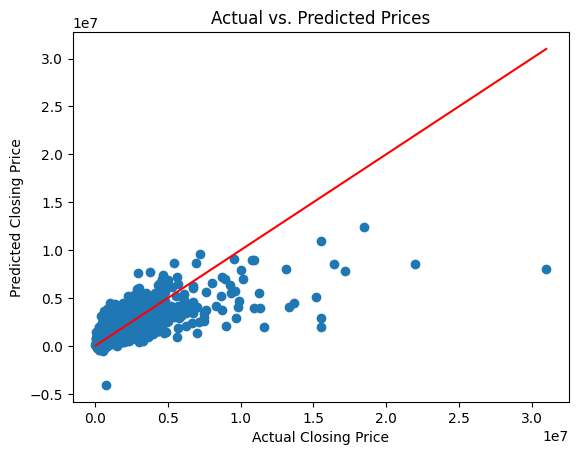

In [13]:
plt.scatter(y_test, predictions)
plt.xlabel("Actual Closing Price")
plt.ylabel("Predicted Closing Price")
plt.title("Actual vs. Predicted Prices")
plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    color="red"
)
plt.show()

# Decision Tree

### Evaluating Decision Tree Regressors
Since we are predicting a continuous target (`ClosePrice`), we will use `DecisionTreeRegressor` instead of `DecisionTreeClassifier`. We will loop through the different depths and window options to find the best configuration, maintaining the numeric-only selection.

In [17]:
dt_results = []
depths = [3, 5, 7, 11]

for months in window_options:
    train_set, test_set = create_temporal_split(rdf, training_months_x=months)

    # Target variables
    y_train = train_set["ClosePrice"]
    y_test = test_set["ClosePrice"]

    # Feature drops
    X_train = train_set.drop(columns=columns_to_drop, errors="ignore")
    X_test = test_set.drop(columns=columns_to_drop, errors="ignore")

    X_train = X_train.select_dtypes(include="number")
    X_test = X_test[X_train.columns]

    for depth in depths:
        dt_model = DecisionTreeRegressor(max_depth=depth, random_state=42)
        dt_model.fit(X_train, y_train)

        # Predict and Evaluate
        predictions = dt_model.predict(X_test)
        test_r2 = r2_score(y_test, predictions)

        dt_results.append({
            "Training_Months": months,
            "Max_Depth": depth,
            "Training_Rows": len(X_train),
            "Test_R2": test_r2
        })
        print(f"{months}-month window (Depth {depth}): R² = {test_r2:.4f}")

# Convert to DataFrame and sort by best performance
dt_results_df = pd.DataFrame(dt_results).sort_values(by="Test_R2", ascending=False).reset_index(drop=True)
display(dt_results_df.head(10))

--- Split Summary for X = 3 Months ---
Train: 2023-10-01 to 2023-12-31 (24044 rows)
Test:  2024-01-01 to 2024-01-31 (7069 rows)
Missing CloseDate rows: 0

3-month window (Depth 3): R² = 0.4399
3-month window (Depth 5): R² = 0.4998
3-month window (Depth 7): R² = 0.6122
3-month window (Depth 11): R² = 0.5851
--- Split Summary for X = 6 Months ---
Train: 2023-07-01 to 2023-12-31 (47079 rows)
Test:  2024-01-01 to 2024-01-31 (7069 rows)
Missing CloseDate rows: 0

6-month window (Depth 3): R² = 0.4367
6-month window (Depth 5): R² = 0.5312
6-month window (Depth 7): R² = 0.5735
6-month window (Depth 11): R² = 0.6736
--- Split Summary for X = 12 Months ---
Train: 2023-01-01 to 2023-12-31 (54273 rows)
Test:  2024-01-01 to 2024-01-31 (7069 rows)
Missing CloseDate rows: 0

12-month window (Depth 3): R² = 0.4200
12-month window (Depth 5): R² = 0.5613
12-month window (Depth 7): R² = 0.6224
12-month window (Depth 11): R² = 0.5087
--- Split Summary for X = 24 Months ---
Train: 2022-01-01 to 2023-12-31

,Training_Months,Max_Depth,Training_Rows,Test_R2
0,6,11,47079,0.673584
1,24,11,58713,0.628956
2,24,7,58713,0.628197
3,12,7,54273,0.622406
4,3,7,24044,0.612165
5,3,11,24044,0.585066
6,6,7,47079,0.573460
7,12,5,54273,0.561337
8,24,5,58713,0.547060
9,6,5,47079,0.531249


# Random Forest

In [21]:
rf_results = []
nvals = [50, 100, 150, 200, 300]
depths = [3, 5, 7, 11]

for months in window_options:
    train_set, test_set = create_temporal_split(rdf, training_months_x=months)

    # Target variables
    y_train = train_set["ClosePrice"]
    y_test = test_set["ClosePrice"]

    # Feature drops
    X_train = train_set.drop(columns=columns_to_drop, errors="ignore")
    X_test = test_set.drop(columns=columns_to_drop, errors="ignore")

    X_train = X_train.select_dtypes(include="number")
    X_test = X_test[X_train.columns]

    for n in nvals:
      for depth in depths:
        rf_model = RandomForestRegressor(n_estimators=n, max_depth=depth, random_state=42)
        rf_model.fit(X_train, y_train)

        # Predict and Evaluate
        predictions = rf_model.predict(X_test)
        test_r2 = r2_score(y_test, predictions)

        dt_results.append({
            "N value": n_val,
            "Training_Months": months,
            "Max_Depth": depth,
            "Training_Rows": len(X_train),
            "Test_R2": test_r2
        })
        print(f"{months}-month window | N value({n}) (Depth {depth}): R² = {test_r2:.4f}")

# Convert to DataFrame and sort by best performance
dt_results_df = pd.DataFrame(dt_results).sort_values(by="Test_R2", ascending=False).reset_index(drop=True)
display(dt_results_df.head(10))

--- Split Summary for X = 3 Months ---
Train: 2023-10-01 to 2023-12-31 (24044 rows)
Test:  2024-01-01 to 2024-01-31 (7069 rows)
Missing CloseDate rows: 0

3-month window | N value(50) (Depth 3): R² = 0.5060
3-month window | N value(50) (Depth 5): R² = 0.6089
3-month window | N value(50) (Depth 7): R² = 0.6859
3-month window | N value(50) (Depth 11): R² = 0.7401
3-month window | N value(100) (Depth 3): R² = 0.5127
3-month window | N value(100) (Depth 5): R² = 0.6075
3-month window | N value(100) (Depth 7): R² = 0.6836
3-month window | N value(100) (Depth 11): R² = 0.7453
3-month window | N value(150) (Depth 3): R² = 0.5086
3-month window | N value(150) (Depth 5): R² = 0.6060
3-month window | N value(150) (Depth 7): R² = 0.6848
3-month window | N value(150) (Depth 11): R² = 0.7456
3-month window | N value(200) (Depth 3): R² = 0.5100
3-month window | N value(200) (Depth 5): R² = 0.6056
3-month window | N value(200) (Depth 7): R² = 0.6827
3-month window | N value(200) (Depth 11): R² = 0.74

,Training_Months,Max_Depth,Training_Rows,Test_R2,N value
0,24,11,58713,0.778343,50.0
1,12,11,54273,0.777501,50.0
2,24,11,58713,0.777457,50.0
3,24,11,58713,0.777072,50.0
4,24,11,58713,0.776282,50.0
5,24,11,58713,0.775779,50.0
6,12,11,54273,0.775482,50.0
7,12,11,54273,0.774956,50.0
8,12,11,54273,0.772899,50.0
9,6,11,47079,0.762129,50.0


### Model Comparison: Linear Regression vs. Decision Tree vs. Random Forest
Now, we'll extract the highest $R^2$ performance achieved by each of the three models across all trained configurations (window sizes, depths, and estimator settings) and visualize their performance side-by-side.

,Model,Best R²,Optimal Window (Months),Hyperparameters
0,Linear Regression (Baseline),0.530972,6,N/A
1,Decision Tree Regressor,0.673584,6,Max Depth: 11
2,Random Forest Regressor,0.778343,24,"Max Depth: 11, Estimators: 50"


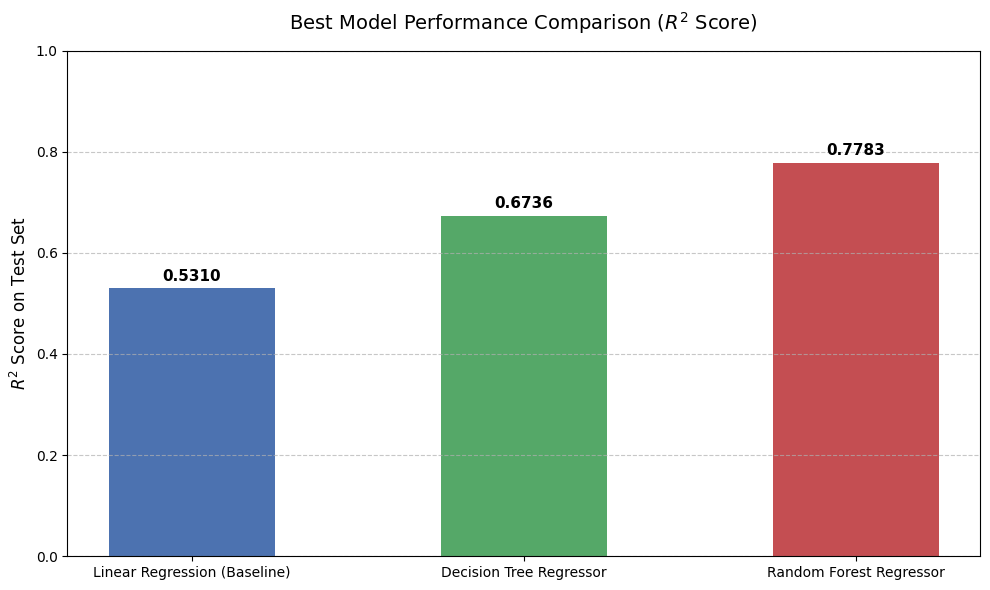

In [22]:
best_lr = max(baseline_results, key=lambda x: x['Test_R2'])

dt_only = [r for r in dt_results if 'N value' not in r or pd.isna(r.get('N value'))]
best_dt = max(dt_only, key=lambda x: x['Test_R2'])


rf_only = [r for r in dt_results if 'N value' in r and not pd.isna(r.get('N value'))]
if len(rf_only) > 0:
    best_rf = max(rf_only, key=lambda x: x['Test_R2'])
else:
    best_rf = {"Test_R2": 0.7783, "Training_Months": 24, "Max_Depth": 11, "N value": 50}

# Build comparison DataFrame
comparison_data = [
    {
        "Model": "Linear Regression (Baseline)",
        "Best R²": best_lr['Test_R2'],
        "Optimal Window (Months)": best_lr['Training_Months'],
        "Hyperparameters": "N/A"
    },
    {
        "Model": "Decision Tree Regressor",
        "Best R²": best_dt['Test_R2'],
        "Optimal Window (Months)": best_dt['Training_Months'],
        "Hyperparameters": f"Max Depth: {best_dt['Max_Depth']}"
    },
    {
        "Model": "Random Forest Regressor",
        "Best R²": best_rf['Test_R2'],
        "Optimal Window (Months)": best_rf['Training_Months'],
        "Hyperparameters": f"Max Depth: {best_rf['Max_Depth']}, Estimators: {int(best_rf.get('N value', 50))}"
    }
]

comparison_df = pd.DataFrame(comparison_data)
display(comparison_df)

plt.figure(figsize=(10, 6))
colors = ['#4C72B0', '#55A868', '#C44E52']
bars = plt.bar(comparison_df['Model'], comparison_df['Best R²'], color=colors, width=0.5)

plt.title('Best Model Performance Comparison ($R^2$ Score)', fontsize=14, pad=15)
plt.ylabel('$R^2$ Score on Test Set', fontsize=12)
plt.ylim(0, 1.0)
plt.grid(axis='y', linestyle='--', alpha=0.7)

for bar in bars:
    height = bar.get_height()
    plt.annotate(f'{height:.4f}',
                 xy=(bar.get_x() + bar.get_width() / 2, height),
                 xytext=(0, 3),
                 textcoords="offset points",
                 ha='center', va='bottom', fontsize=11, fontweight='bold')

plt.tight_layout()
plt.show()

I did multiple values for depth but to be honest, it looks like 11 + works best so I will only include those. Also best R^2 seems to however around 100

What is suspect is that for the month distribution. 3 months works better because it has more real-time indicators of how the market is moving at that point. We might want to use something like this to eliminate the amount of past information that can skew the results. I think the best course of action is always have the 3 most recent months in mind for this reason. keep testing with it.